In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/full_datasets/gfs_hamburg_t2m_precip.csv",
                 parse_dates=["init_time", "valid_time"]
)

df.head()

,init_time,lead_time_h,valid_time,temperature_2m,precipitation_surface,latitude,longitude
0,2024-04-01,0.0,2024-04-01 00:00:00,7.43750,NaN,53.75,10.0
1,2024-04-01,1.0,2024-04-01 01:00:00,6.81250,0.0,53.75,10.0
2,2024-04-01,2.0,2024-04-01 02:00:00,6.56250,0.0,53.75,10.0
3,2024-04-01,3.0,2024-04-01 03:00:00,6.78125,0.0,53.75,10.0
4,2024-04-01,4.0,2024-04-01 04:00:00,6.75000,0.0,53.75,10.0


In [2]:
print(f"Anzahl Datensätze: {len(df):,}")

print("Erster Forecast:",
      df["init_time"].min())

print("Letzter Forecast:",
      df["init_time"].max())

Anzahl Datensätze: 200,849
Erster Forecast: 2024-04-01 00:00:00
Letzter Forecast: 2026-11-17 00:00:00


In [ ]:
#Zeiten vollständig?

In [3]:
expected_inits = pd.date_range(
    start=df["init_time"].min(),
    end=df["init_time"].max(),
    freq="D"
)

actual_inits = pd.DatetimeIndex(
    sorted(df["init_time"].unique())
)

missing_inits = expected_inits.difference(actual_inits)

print(
    f"Fehlende Forecast-Tage: {len(missing_inits)}"
)

missing_inits[:20]

Fehlende Forecast-Tage: 0


DatetimeIndex([], dtype='datetime64[us]', freq='D')

In [4]:
lead_times = sorted(
    df["lead_time_h"].unique()
)

print(
    f"Anzahl Lead Times: {len(lead_times)}"
)

lead_times[:50]

Anzahl Lead Times: 209


[np.float64(0.0),
 np.float64(1.0),
 np.float64(2.0),
 np.float64(3.0),
 np.float64(4.0),
 np.float64(5.0),
 np.float64(6.0),
 np.float64(7.0),
 np.float64(8.0),
 np.float64(9.0),
 np.float64(10.0),
 np.float64(11.0),
 np.float64(12.0),
 np.float64(13.0),
 np.float64(14.0),
 np.float64(15.0),
 np.float64(16.0),
 np.float64(17.0),
 np.float64(18.0),
 np.float64(19.0),
 np.float64(20.0),
 np.float64(21.0),
 np.float64(22.0),
 np.float64(23.0),
 np.float64(24.0),
 np.float64(25.0),
 np.float64(26.0),
 np.float64(27.0),
 np.float64(28.0),
 np.float64(29.0),
 np.float64(30.0),
 np.float64(31.0),
 np.float64(32.0),
 np.float64(33.0),
 np.float64(34.0),
 np.float64(35.0),
 np.float64(36.0),
 np.float64(37.0),
 np.float64(38.0),
 np.float64(39.0),
 np.float64(40.0),
 np.float64(41.0),
 np.float64(42.0),
 np.float64(43.0),
 np.float64(44.0),
 np.float64(45.0),
 np.float64(46.0),
 np.float64(47.0),
 np.float64(48.0),
 np.float64(49.0)]

In [5]:
forecast_sizes = (
    df.groupby("init_time")
      .size()
)

forecast_sizes.describe()

count    961.0
mean     209.0
std        0.0
min      209.0
25%      209.0
50%      209.0
75%      209.0
max      209.0
dtype: float64

In [6]:
EXPECTED_ROWS = 209
forecast_sizes[
    forecast_sizes != EXPECTED_ROWS
]

Series([], dtype: int64)

In [7]:
missing = pd.DataFrame({
    "count": df.isna().sum(),
    "percent":
        100 * df.isna().sum() / len(df)
})

display(missing)

,count,percent
init_time,0,0.000000
lead_time_h,0,0.000000
valid_time,0,0.000000
temperature_2m,0,0.000000
precipitation_surface,961,0.478469
latitude,0,0.000000
longitude,0,0.000000


In [ ]:
#Temperaturverteilung

In [8]:
df["temperature_2m"].describe()

count    200849.000000
mean         10.874847
std           6.983375
min         -14.875000
25%           5.781250
50%          11.000000
75%          15.687500
max          43.250000
Name: temperature_2m, dtype: float64

In [9]:
print("Minimum:",
      df["temperature_2m"].min())

print("Maximum:",
      df["temperature_2m"].max())

Minimum: -14.875
Maximum: 43.25


In [10]:
outliers = df[
    (df["temperature_2m"] < -50) |
    (df["temperature_2m"] > 50)
]

print(
    f"Verdächtige Datensätze: {len(outliers)}"
)

outliers.head()

Verdächtige Datensätze: 0


,init_time,lead_time_h,valid_time,temperature_2m,precipitation_surface,latitude,longitude


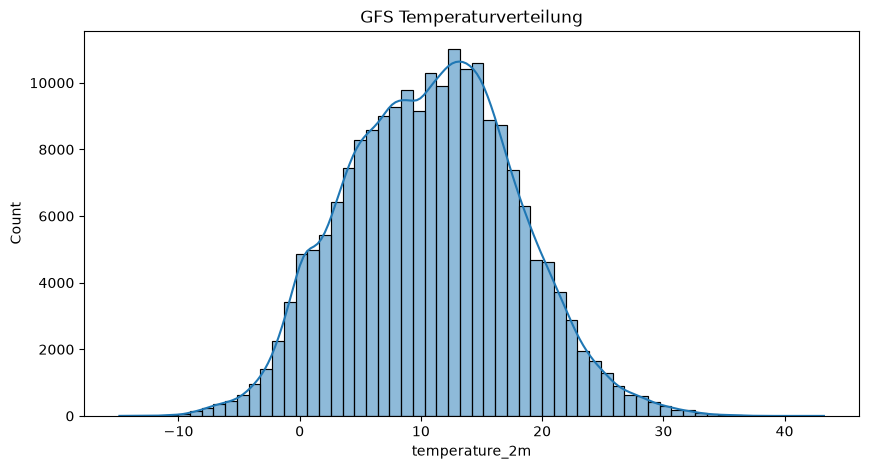

In [11]:
plt.figure(figsize=(10,5))

sns.histplot(
    df["temperature_2m"],
    bins=60,
    kde=True
)

plt.title(
    "GFS Temperaturverteilung"
)

plt.show()

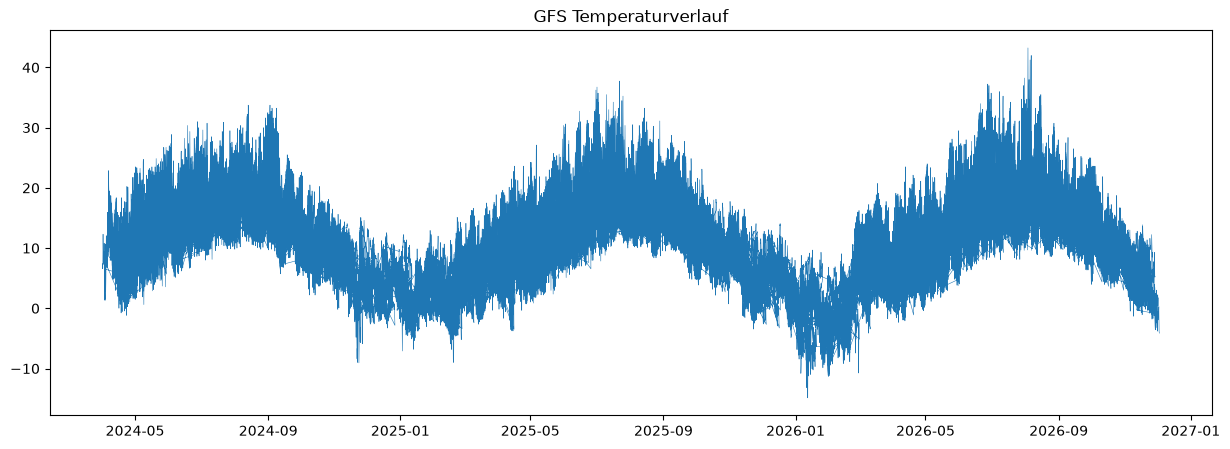

In [12]:
plt.figure(figsize=(15,5))

plt.plot(
    df["valid_time"],
    df["temperature_2m"],
    linewidth=0.4
)

plt.title(
    "GFS Temperaturverlauf"
)

plt.show()

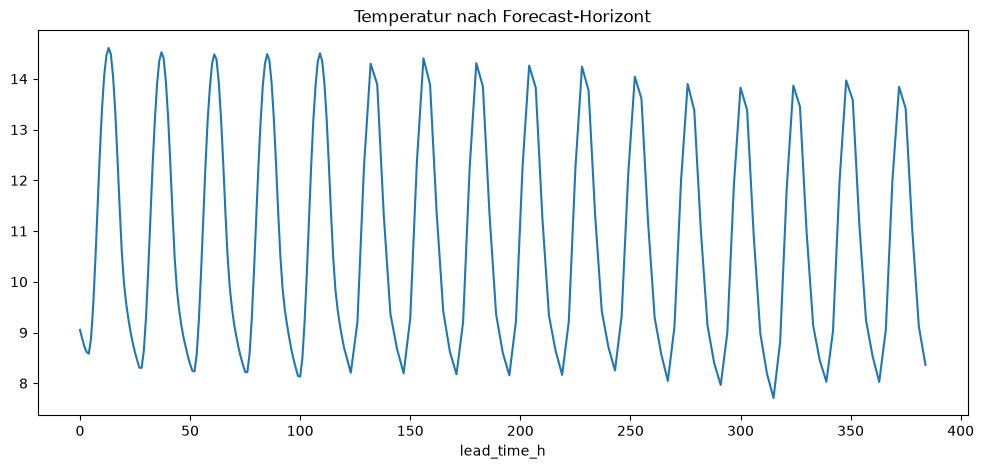

In [13]:
mean_by_lead = (
    df.groupby("lead_time_h")
      ["temperature_2m"]
      .mean()
)

plt.figure(figsize=(12,5))

mean_by_lead.plot()

plt.title(
    "Temperatur nach Forecast-Horizont"
)

plt.show()

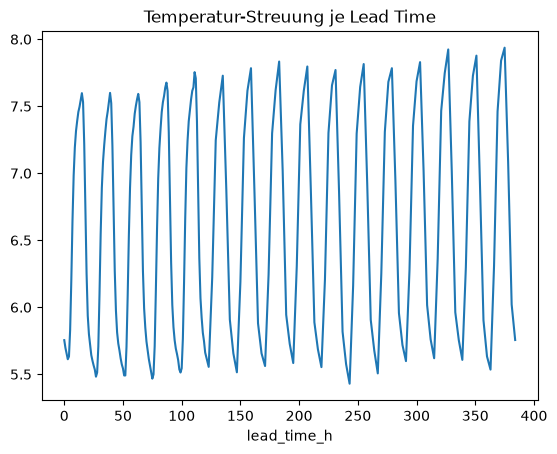

In [14]:
std_by_lead = (
    df.groupby("lead_time_h")
      ["temperature_2m"]
      .std()
)

std_by_lead.plot()

plt.title(
    "Temperatur-Streuung je Lead Time"
)

plt.show()

In [ ]:
#weiß immer noch, was das bedeutet

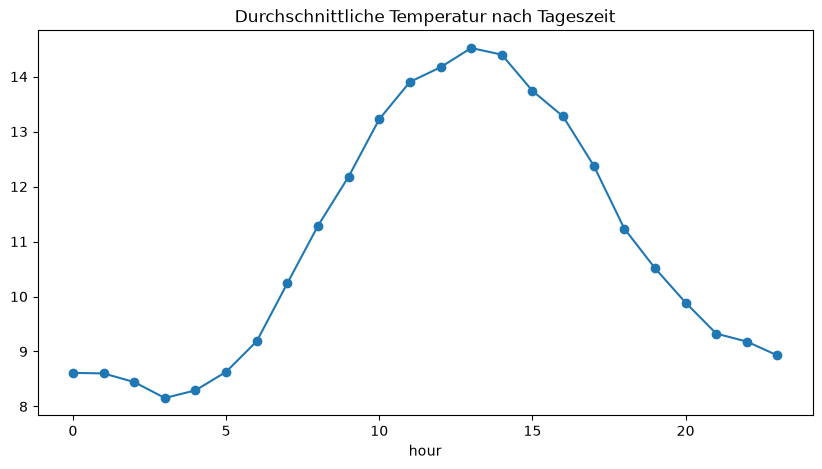

In [15]:
df["hour"] = (
    df["valid_time"]
      .dt.hour
)

hourly = (
    df.groupby("hour")
      ["temperature_2m"]
      .mean()
)

plt.figure(figsize=(10,5))

hourly.plot(marker="o")

plt.title(
    "Durchschnittliche Temperatur nach Tageszeit"
)

plt.show()

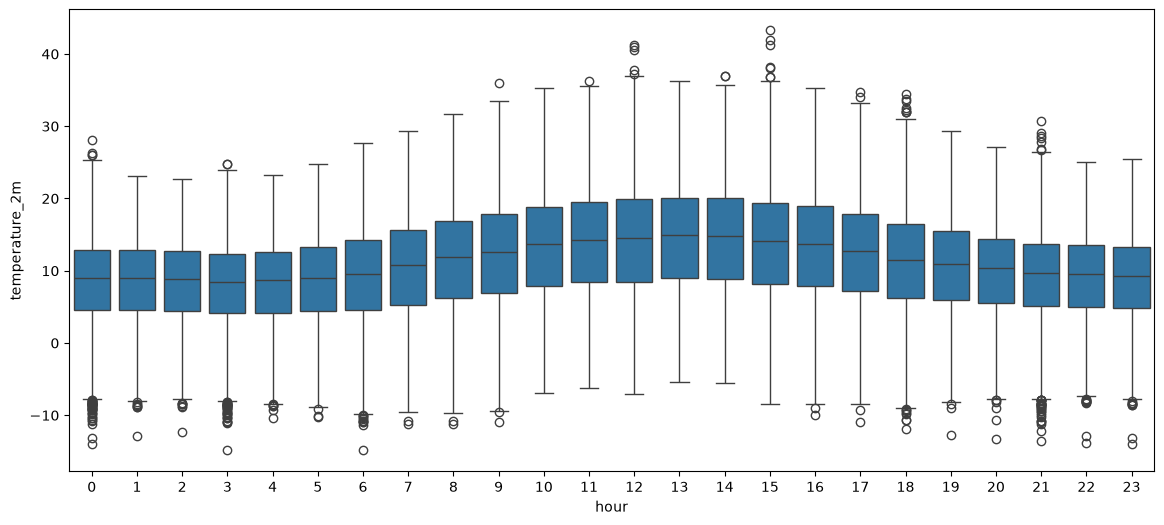

In [16]:
plt.figure(figsize=(14,6))

sns.boxplot(
    data=df,
    x="hour",
    y="temperature_2m"
)

plt.show()

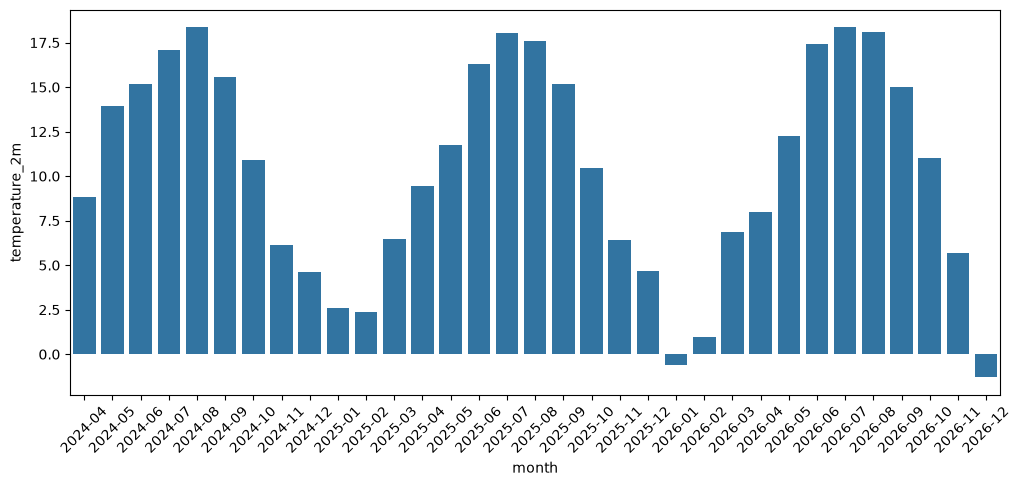

In [17]:

df["month"] = (
    df["valid_time"]
      .dt.to_period("M")
)


monthly = (
    df.groupby("month")
      ["temperature_2m"]
      .mean()
      .reset_index()
)

monthly["month"] = (
    monthly["month"]
    .astype(str)
)

plt.figure(figsize=(12,5))

sns.barplot(
    data=monthly,
    x="month",
    y="temperature_2m"
)

plt.xticks(rotation=45)

plt.show()

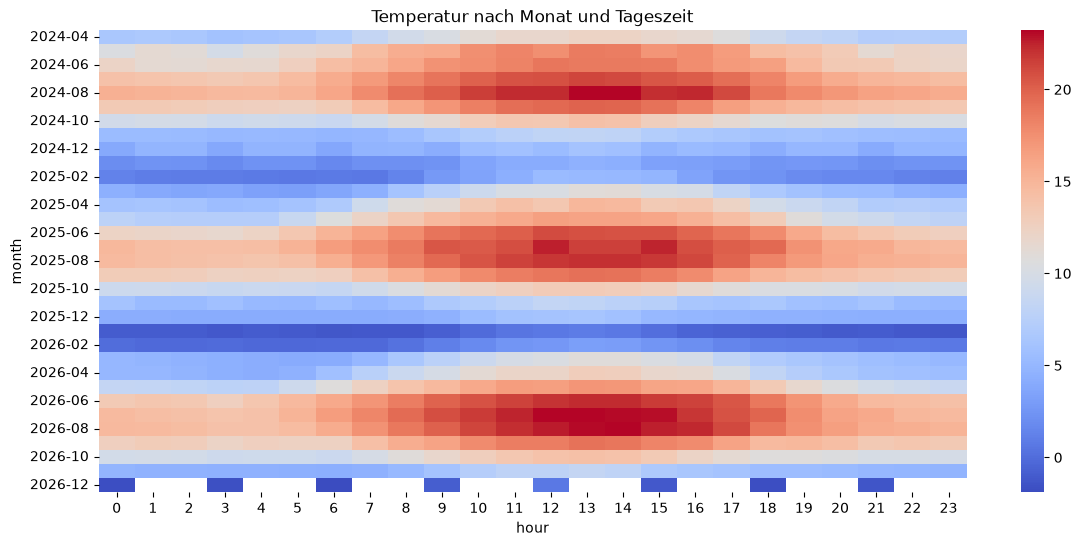

In [18]:
heatmap_data = (
    df.groupby(
        ["month","hour"]
    )["temperature_2m"]
      .mean()
      .unstack()
)

plt.figure(figsize=(14,6))

sns.heatmap(
    heatmap_data,
    cmap="coolwarm"
)

plt.title(
    "Temperatur nach Monat und Tageszeit"
)

plt.show()

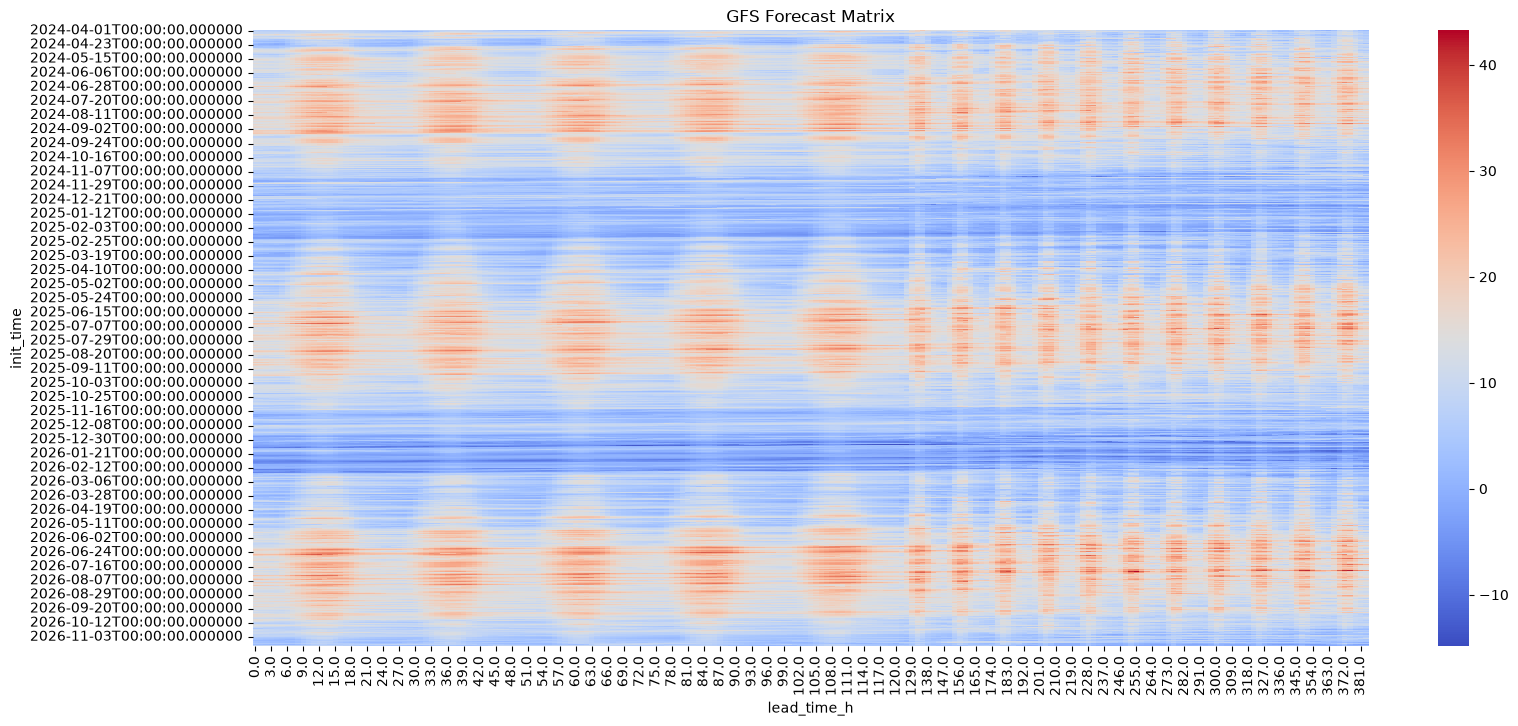

In [19]:
forecast_matrix = (
    df.pivot_table(
        index="init_time",
        columns="lead_time_h",
        values="temperature_2m"
    )
)

plt.figure(figsize=(18,8))

sns.heatmap(
    forecast_matrix,
    cmap="coolwarm"
)

plt.title(
    "GFS Forecast Matrix"
)

plt.show()